# Customer Support Analysis - Data Cleaning

Explores customer support interactions with AppleSupport and AmazonHelp in the Customer Support on Twitter dataset. 

We examine 
- how posting time, message wording, 
- and planned shopping peaks versus unexpected technical issues relate to response times, 
- providing a foundation for similar-case retrieval and waiting-time estimation.

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Data Cleaning

### 1. Read Data

In [72]:
df = pd.read_csv("../data/twcs/twcs.csv")
print("Data Shape: ", df.shape)
df.head(10)

Data Shape:  (2811774, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0
5,6,sprintcare,False,Tue Oct 31 21:46:24 +0000 2017,@115712 Can you please send us a private messa...,"5,7",8.0
6,8,115712,True,Tue Oct 31 21:45:10 +0000 2017,@sprintcare is the worst customer service,"9,6,10",NaN
7,11,sprintcare,False,Tue Oct 31 22:10:35 +0000 2017,@115713 This is saddening to hear. Please shoo...,NaN,12.0
8,12,115713,True,Tue Oct 31 22:04:47 +0000 2017,@sprintcare You gonna magically change your co...,"11,13,14",15.0
9,15,sprintcare,False,Tue Oct 31 20:03:31 +0000 2017,@115713 We understand your concerns and we'd l...,12,16.0


Each row represents one tweet.

- `tweet_id`: The unique ID of the tweet.
- `author_id`: The ID or account name of the person or support team that posted the tweet.
- `inbound`: Whether the tweet was sent to a company. `True`: a customer message. `False`: a support message.
- `created_at`: The date and time when the tweet was posted.
- `text`: The text of the tweet.
- `response_tweet_id`: The ID(s) of tweets that replied to this tweet, if any.
- `in_response_to_tweet_id`: The ID of the tweet that this tweet replied to, if any.

### 2. Check Missing Value

In [73]:
missing_values = pd.DataFrame({"Missing Count": df.isnull().sum()})
missing_values = missing_values.sort_values("Missing Count", ascending=False)
missing_values

,Missing Count
response_tweet_id,1040629
in_response_to_tweet_id,794335
tweet_id,0
author_id,0
inbound,0
created_at,0
text,0


- Missing `response_tweet_id`: no reply to this tweet is recorded in the dataset.
- Missing `in_response_to_tweet_id`: this tweet is not recorded as a reply to another tweet. It may be the start of a conversation.
- Both are missing: neither field records a reply link, so the tweet may be a standalone message.

Missing IDs do not tell us whether the author is a customer or a support account.

In [74]:
both_missing = df[df["response_tweet_id"].isnull() & df["in_response_to_tweet_id"].isnull()]
print("Tweets with both IDs missing:", both_missing.shape[0])

Tweets with both IDs missing: 0


No tweet has both reply ID fields missing. Based on the recorded IDs, every tweet falls into one of three cases:

- It replies to another tweet, but has no recorded reply.
- It has a reply, but is not recorded as replying to another tweet.
- It replies to another tweet and also has a reply, so it is in the middle of a conversation.

### 3. Check Repeated Value

In [75]:
print("Exact duplicate rows:", df.duplicated().sum())

id_counts = df["tweet_id"].value_counts()
print("Number of repeated tweet IDs:", (id_counts > 1).sum())

Exact duplicate rows: 0
Number of repeated tweet IDs: 0


The dataset contains no exact duplicate rows, and every `tweet_id` is unique. 
No rows need to be removed as duplicates.

### 4. Brand Statistics

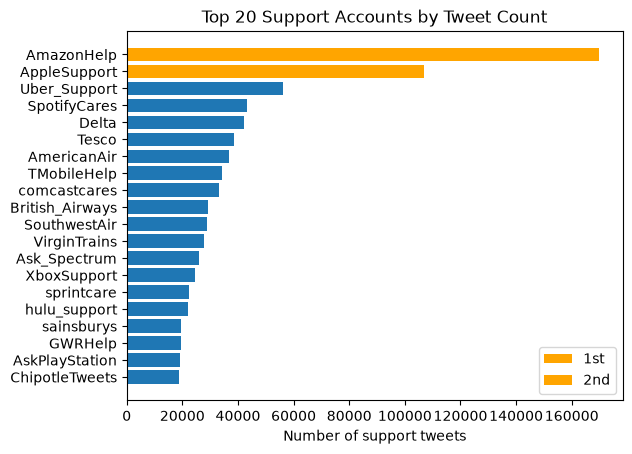

In [76]:
support_tweets = df[df["inbound"] == False]
brand_counts = pd.DataFrame({"Support Tweet Count": support_tweets["author_id"].value_counts()})
top_brands = brand_counts.head(20).sort_values("Support Tweet Count")

plt.barh(top_brands.index, top_brands["Support Tweet Count"])
plt.barh(top_brands.index[-1], top_brands["Support Tweet Count"].iloc[-1], color="orange", label="1st")
plt.barh(top_brands.index[-2], top_brands["Support Tweet Count"].iloc[-2], color="orange", label="2nd")
plt.xlabel("Number of support tweets")
plt.title("Top 20 Support Accounts by Tweet Count")
plt.legend()
plt.show()

The chart shows the 20 support accounts with the most tweets. 
AmazonHelp has the most support tweets, followed by AppleSupport. 
For the rest of this project, we will study only Amazon and Apple, including their support tweets and related customer messages.

In [77]:
def find_related_brands(data):
    """Fill unknown brands one reply step at a time using pandas.
    Keep the first assigned brand and return a Series aligned with data.
    """
    # First label the support tweet.
    messages = data[["tweet_id", "in_response_to_tweet_id"]].copy()
    messages["related_brand"] = data["author_id"].where(data["inbound"] == False)
    # Now, only support tweets have the label.
    # new_labels is the latest updated data every iteration.
    new_labels = messages[messages["related_brand"].notna()]
    # unknown is those who haven't been updated.
    unknown = messages[messages["related_brand"].isna()].copy()

    # Only newly labeled tweets need to pass their brand to unknown tweets.
    while not new_labels.empty and not unknown.empty:
        parent_brand = new_labels.set_index("tweet_id")["related_brand"]
        reply_brand = new_labels.groupby("in_response_to_tweet_id")["related_brand"].first()
        # Within each round, use the parent's brand before a reply's brand.
        unknown["related_brand"] = unknown["in_response_to_tweet_id"].map(parent_brand)
        unknown["related_brand"] = unknown["related_brand"].fillna(unknown["tweet_id"].map(reply_brand))
        new_labels = unknown[unknown["related_brand"].notna()]
        messages.loc[new_labels.index, "related_brand"] = new_labels["related_brand"]
        unknown = unknown[unknown["related_brand"].isna()].copy()

    return messages["related_brand"]

cleaned_df = df.copy()

# Add brand labels, then keep tweets related to Amazon or Apple.
cleaned_df["related_brand"] = find_related_brands(cleaned_df)
print("Tweets before filtering:", cleaned_df.shape[0])
cleaned_df = cleaned_df[cleaned_df["related_brand"].isin(["AmazonHelp", "AppleSupport"])].copy()
print("Tweets after filtering:", cleaned_df.shape[0])
cleaned_df[["tweet_id", "author_id", "inbound", "related_brand"]].head(10)

Tweets before filtering: 2811774
Tweets after filtering: 611145


,tweet_id,author_id,inbound,related_brand
181,269,AmazonHelp,False,AmazonHelp
182,270,115770,True,AmazonHelp
183,271,115770,True,AmazonHelp
184,273,AmazonHelp,False,AmazonHelp
185,274,115770,True,AmazonHelp
186,275,AmazonHelp,False,AmazonHelp
187,272,115770,True,AmazonHelp
234,324,AmazonHelp,False,AmazonHelp
235,325,115792,True,AmazonHelp
321,615,AmazonHelp,False,AmazonHelp


### 5. Check Data Types

In [78]:
pd.DataFrame({"Data Type": cleaned_df.dtypes})

,Data Type
tweet_id,int64
author_id,str
inbound,bool
created_at,str
text,str
response_tweet_id,str
in_response_to_tweet_id,float64
related_brand,str


In [79]:
multiple_replies = cleaned_df[cleaned_df["response_tweet_id"].str.contains(",", na=False)]
print("Tweets with multiple reply IDs:", multiple_replies.shape[0])
multiple_replies[["tweet_id", "response_tweet_id", "in_response_to_tweet_id"]].head()

Tweets with multiple reply IDs: 43009


,tweet_id,response_tweet_id,in_response_to_tweet_id
181,269,"270,271",272.0
378,672,"671,673,674",NaN
382,678,"677,679",NaN
385,682,"681,683",NaN
389,686,"684,688",689.0


- `tweet_id` is `int64`: it contains integer IDs with no missing values.
- `in_response_to_tweet_id` is `float64`: it contains missing values (`NaN`), which regular `int64` cannot store.
- `response_tweet_id` is `str`: some values contain several reply IDs separated by commas, such as `"5,7"`.

In [80]:
# Convert the str into list
response_ids = []
for response in cleaned_df["response_tweet_id"].fillna(""):
    response_ids.append([int(x) for x in response.split(",") if x != ""])

cleaned_df["response_tweet_id"] = response_ids
# Change type to Int64 (can store NaN)
cleaned_df["tweet_id"] = cleaned_df["tweet_id"].astype("Int64")
cleaned_df["in_response_to_tweet_id"] = cleaned_df["in_response_to_tweet_id"].astype("Int64")

In [81]:
pd.DataFrame({"Data Type": cleaned_df.dtypes})

,Data Type
tweet_id,Int64
author_id,str
inbound,bool
created_at,str
text,str
response_tweet_id,object
in_response_to_tweet_id,Int64
related_brand,str


In [84]:
cleaned_df[["tweet_id", "response_tweet_id", "in_response_to_tweet_id"]].head(10)

,tweet_id,response_tweet_id,in_response_to_tweet_id
181,269,"[270, 271]",272
182,270,[],269
183,271,[273],269
184,273,[274],271
185,274,[275],273
186,275,[],274
187,272,[269],<NA>
234,324,[],325
235,325,[324],<NA>
321,615,[616],617


### 6. Filter English Tweets

In [ ]:
# import re
# from langdetect import DetectorFactory, detect
# from langdetect.lang_detect_exception import LangDetectException

# DetectorFactory.seed = 1007


# def detect_language(text):
#     """Detect a tweet's language after removing links and mentions, or return unknown."""
#     text = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", text)
#     try:
#         return detect(text)
#     except LangDetectException:
#         return "unknown"


# print("Tweets before language filtering:", cleaned_df.shape[0])
# cleaned_df["language"] = cleaned_df["text"].apply(detect_language)
# cleaned_df = cleaned_df[cleaned_df["language"] == "en"].copy()
# print("Tweets detected as English:", cleaned_df.shape[0])
# cleaned_df[["tweet_id", "text", "language", "related_brand"]].head(10)


Tweets before language filtering: 611145
Tweets detected as English: 507873


,tweet_id,text,language,related_brand
321,615,@115820 I'm sorry we've let you down! Without ...,en,AmazonHelp
322,616,@AmazonHelp 3 different people have given 3 di...,en,AmazonHelp
323,618,@115820 We'd like to take a further look into ...,en,AmazonHelp
324,619,@AmazonHelp I frankly don't have the patience ...,en,AmazonHelp
325,617,Way to drop the ball on customer service @1158...,en,AmazonHelp
326,620,@115822 I am unable to affect your account via...,en,AmazonHelp
327,621,@115823 I want my amazon payments account CLOS...,en,AmazonHelp
332,626,@115826 I'm sorry for the wait. You'll receive...,en,AmazonHelp
333,627,@AmazonHelp @115826 Yeah this is crazy we’re l...,en,AmazonHelp
334,629,@115827 Thanks for your patience. ^KM,en,AmazonHelp


In [86]:
cleaned_df.shape

(507873, 9)

In [ ]:
# cleaned_df.to_pickle("../data/cleaned_df.pkl")
# print("Saved", cleaned_df.shape[0], "tweets to ../data/cleaned_df.pkl")


Saved 507873 tweets to ../outputs/cleaned_df.pkl
